## **Apriori**

Apriori finds the **frequent itemsets** level by level: it joins the frequent (k-1)-itemsets into k-candidates, **prunes** every candidate that has an infrequent subset ( the *Apriori property* ) and counts the support of the survivors.
The algorithm is written from scratch with bit-sets and then **audited with quality metrics**: precision and recall against a brute-force ground truth, the downward closure property, candidates saved by the pruning and scalability.

**Notebooks of this series:** 1. Apriori · 2. FP-Growth · 3. Eclat · 4. Comparing the Algorithms · 5. Association Rules ( Generation, Reduction and Evaluation ) · 6. Interestingness Measures · 7. Sequential Patterns ( SPADE ) · 8. High-Utility Itemsets · 9. Associative Classification ( CBA )

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

### **1. Association Rule Mining**

Finds **items that occur together** (market-basket analysis) in two steps:

1. **Frequent itemsets:** all sets of items with support ≥ *min_support*
2. **Rules** $A \Rightarrow B$ from those itemsets, filtered by confidence, lift…

| Algorithm | Strategy | Key idea |
|---|---|---|
| **Apriori** | breadth-first, level by level | *a superset of an infrequent set is infrequent* (pruning) |
| **FP-Growth** | divide and conquer | compress the data in an **FP-tree**; no candidate generation |
| **Eclat** | depth-first on **tid-lists** | support = size of the **intersection** of transaction lists |

All three return **exactly the same itemsets** ( checked in notebook *4. Comparing the Algorithms* ).

### **2. Dataset: Simulated Retail Baskets**

6 000 baskets generated from **shopper profiles** (breakfast, party, family dinner, baby, healthy), so that natural associations appear, a mild unexpected one (*diapers ⟶ beer*) and a **loyalty-card bundle** (diapers always come with the baby club card).

In [4]:
#Generate the Transactions ( Shopper Profiles + Random Background Items )
rng = np.random.default_rng(RANDOM_STATE)
profiles = {
    "breakfast":     {"bread": .70, "butter": .50, "jam": .35, "milk": .60, "coffee": .50, "sugar": .30, "eggs": .40, "cereal": .30},
    "party":         {"beer": .60, "chips": .60, "soda": .50, "pizza": .35, "ice": .30, "peanuts": .30},
    "family dinner": {"pasta": .60, "tomato_sauce": .50, "cheese": .40, "chicken": .40, "rice": .40, "beans": .30, "salad": .30, "tomato": .30},
    "baby":          {"diapers": .80, "baby_food": .50, "wipes": .50, "milk": .40, "beer": .25},
    "healthy":       {"salad": .60, "fruit": .70, "yogurt": .50, "fish": .40, "lemon": .30, "water": .60, "tomato": .30},
}
items = sorted({i for p in profiles.values() for i in p} | {"baby_club_card"})

def make_basket():
    chosen = rng.choice(list(profiles), size=1 if rng.random() < 0.75 else 2, replace=False)
    basket = {i for p in chosen for i, prob in profiles[p].items() if rng.random() < prob}
    basket |= {i for i in items if rng.random() < 0.025}                      # random background items
    if "diapers" in basket:
        basket.add("baby_club_card")                                           # loyalty-card bundle (always together)
    return frozenset(basket) if basket else frozenset([str(rng.choice(items))])

transactions = [make_basket() for _ in range(6000)]
print("transactions:", len(transactions), "| distinct items:", len(items), "| mean basket size:", round(np.mean([len(t) for t in transactions]), 2))
for t in transactions[:3]:
    print("  ", sorted(t))

transactions: 6000 | distinct items: 31 | mean basket size: 4.72
   ['beans', 'fruit', 'pasta', 'tomato', 'water']
   ['fruit', 'salad', 'tomato_sauce']
   ['fish', 'fruit', 'salad', 'yogurt']


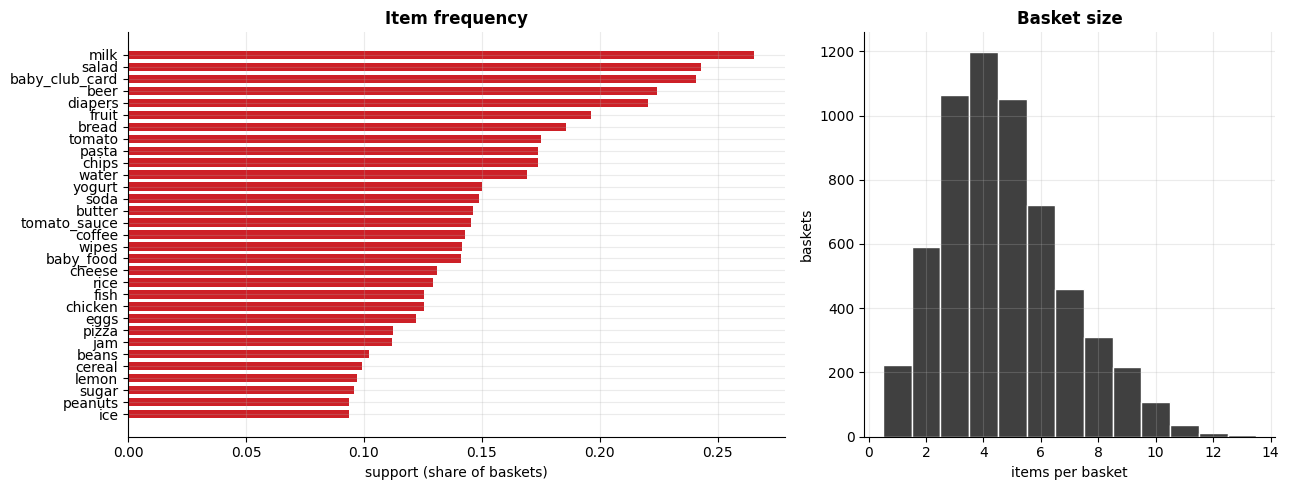

In [5]:
#Explore the Data ( Item Frequency and Basket Size )
freq_items = pd.Series({i: sum(i in t for t in transactions) / len(transactions) for i in items}).sort_values()
sizes = pd.Series([len(t) for t in transactions])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].barh(freq_items.index, freq_items.values, color=RED, height=0.7); axes[0].set_xlabel("support (share of baskets)"); axes[0].set_title("Item frequency")
axes[1].hist(sizes, bins=range(1, sizes.max() + 2), color=DARK, edgecolor="white", align="left"); axes[1].set_xlabel("items per basket"); axes[1].set_ylabel("baskets"); axes[1].set_title("Basket size")
plt.tight_layout(); plt.show()

### **3. Rule Metrics**

For a rule $A \Rightarrow B$ (all supports are shares of the baskets):

| Metric | Formula | Reading |
|---|---|---|
| **Support** | $P(A \cap B)$ | how frequent |
| **Confidence** | $P(B \mid A)$ | how reliable |
| **Lift** | $\dfrac{P(B \mid A)}{P(B)}$ | $>1$ positive · $=1$ independent · $<1$ negative |
| **Leverage** | $P(A \cap B) - P(A)P(B)$ | excess co-occurrence over independence |
| **Conviction** | $\dfrac{1 - P(B)}{1 - \text{conf}}$ | how much $A$ without $B$ is *unexpected* ($\infty$ if conf = 1) |
| **Zhang's** | $\dfrac{\text{leverage}}{\max\{P(AB)(1-P(A)),\ P(A)(P(B)-P(AB))\}}$ | association from −1 to +1 |

In [6]:
#Bit-Set Representation ( One Integer per Item = Its Transaction List ) and Rule-Metric Function
from itertools import combinations
from collections import Counter, defaultdict
import time

def build_tidsets(transactions):
    tid = defaultdict(int)
    for t_idx, basket in enumerate(transactions):
        bit = 1 << t_idx
        for item in basket:
            tid[item] |= bit
    return dict(tid)

def rule_metrics(s_a, s_b, s_ab):
    conf = s_ab / s_a
    lev = s_ab - s_a * s_b
    denom = max(s_ab * (1 - s_a), s_a * (s_b - s_ab))
    return {"support": s_ab, "confidence": conf, "lift": conf / s_b, "leverage": lev,
            "conviction": (1 - s_b) / (1 - conf) if conf < 1 else np.inf, "zhangs": lev / denom if denom > 0 else 0.0}

tid_all = build_tidsets(transactions)
N = len(transactions)
print("support(beer) =", tid_all["beer"].bit_count() / N, "| support(diapers) =", tid_all["diapers"].bit_count() / N)
for a, b in [("diapers", "beer"), ("diapers", "baby_club_card")]:
    print(f"rule {a} => {b}:", {k: round(v, 3) for k, v in rule_metrics(tid_all[a].bit_count() / N, tid_all[b].bit_count() / N, (tid_all[a] & tid_all[b]).bit_count() / N).items()})

support(beer) = 0.22433333333333333 | support(diapers) = 0.22033333333333333
rule diapers => beer: {'support': 0.066, 'confidence': 0.301, 'lift': 1.342, 'leverage': 0.017, 'conviction': 1.11, 'zhangs': 0.327}
rule diapers => baby_club_card: {'support': 0.22, 'confidence': 1.0, 'lift': 4.152, 'leverage': 0.167, 'conviction': inf, 'zhangs': 0.974}


### **4. Apriori**

Level by level: **join** frequent $(k{-}1)$-itemsets into $k$-candidates, **prune** candidates that have an infrequent subset and **count** the support of the rest.
Counting uses the **bit-set** of each item (support = number of 1-bits of the AND).

In [7]:
#Apriori Implementation ( Join, Prune and Count ) with Statistics per Level
def apriori(tid, n, min_support):
    min_count = int(np.ceil(min_support * n))
    level = {(i,): m for i, m in sorted(tid.items()) if m.bit_count() >= min_count}
    freq = {k: m.bit_count() for k, m in level.items()}
    stats = [{"k": 1, "joined": len(tid), "after pruning": len(tid), "frequent": len(level)}]
    k = 1
    while level:
        keys = sorted(level)
        prev, cands, joined = set(keys), {}, 0
        for a in range(len(keys)):
            for b in range(a + 1, len(keys)):
                if keys[a][:-1] != keys[b][:-1]:
                    break
                joined += 1
                new = keys[a] + (keys[b][-1],)
                if all(sub in prev for sub in combinations(new, k)):                          # prune: every k-subset must be frequent
                    cands[new] = level[keys[a]] & level[keys[b]]
        level = {c: m for c, m in cands.items() if m.bit_count() >= min_count}
        k += 1
        if joined:
            stats.append({"k": k, "joined": joined, "after pruning": len(cands), "frequent": len(level)})
        freq.update({c: m.bit_count() for c, m in level.items()})
    return {frozenset(c): v / n for c, v in freq.items()}, pd.DataFrame(stats)

t0 = time.perf_counter()
freq_apriori, apriori_stats = apriori(tid_all, N, min_support=0.02)
t_apriori = time.perf_counter() - t0
print(f"frequent itemsets (support ≥ 2%): {len(freq_apriori)} | time: {t_apriori:.2f}s")
apriori_stats

frequent itemsets (support ≥ 2%): 326 | time: 0.00s


,k,joined,after pruning,frequent
0,1,31,31,31
1,2,465,465,150
2,3,548,331,124
3,4,129,67,20
4,5,3,2,1


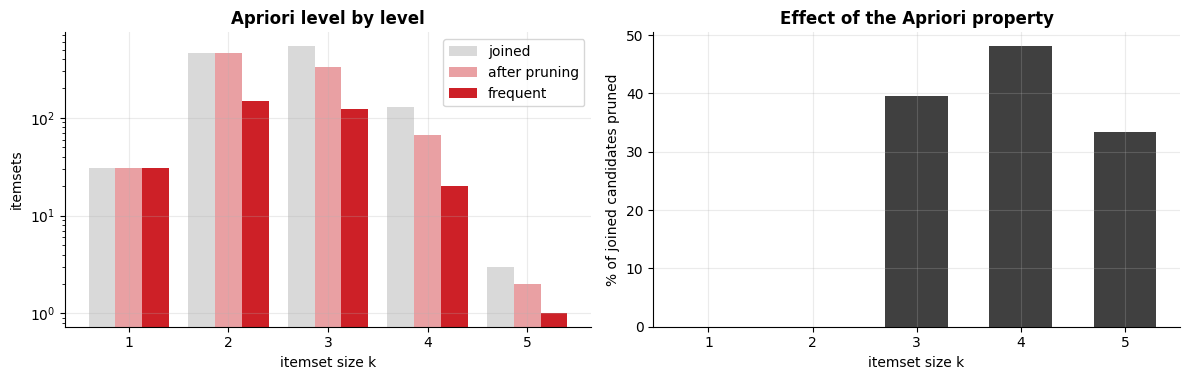

database passes (support counting) = 5 | candidates counted: 896


In [8]:
#Apriori-Specific Metrics: Candidates Generated, Pruned and Frequent per Level
st = apriori_stats
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
x = np.arange(len(st))
axes[0].bar(x - 0.27, st["joined"], 0.27, color=LIGHT, label="joined"); axes[0].bar(x, st["after pruning"], 0.27, color=SOFT, label="after pruning"); axes[0].bar(x + 0.27, st["frequent"], 0.27, color=RED, label="frequent")
axes[0].set_xticks(x); axes[0].set_xticklabels(st["k"]); axes[0].set_xlabel("itemset size k"); axes[0].set_ylabel("itemsets"); axes[0].set_yscale("log"); axes[0].set_title("Apriori level by level"); axes[0].legend()
pruned = (st["joined"] - st["after pruning"]).clip(lower=0)
axes[1].bar(x, pruned / st["joined"].replace(0, 1) * 100, color=DARK, width=0.6); axes[1].set_xticks(x); axes[1].set_xticklabels(st["k"]); axes[1].set_xlabel("itemset size k"); axes[1].set_ylabel("% of joined candidates pruned"); axes[1].set_title("Effect of the Apriori property")
plt.tight_layout(); plt.show()
print("database passes (support counting) =", len(st), "| candidates counted:", int(st["after pruning"].sum()))

### **5. Auditing Apriori ( Quality Metrics )**

In [ ]:
#Join and Prune Step by Step ( Level 3: Which Candidates Were Discarded and Why )
L2 = sorted(tuple(sorted(s)) for s in freq_apriori if len(s) == 2)
L2_set = set(L2)
counted, pruned = [], []
for a in range(len(L2)):
    for b in range(a + 1, len(L2)):
        if L2[a][0] != L2[b][0]:
            break                                                          # the join only combines itemsets that share the first item
        candidate = L2[a] + (L2[b][-1],)
        infrequent_subsets = [sub for sub in combinations(candidate, 2) if sub not in L2_set]
        (pruned if infrequent_subsets else counted).append((candidate, infrequent_subsets))

print(f'3-candidates produced by the join: {len(counted) + len(pruned)} | discarded by the Apriori property: {len(pruned)} | counted in the database: {len(counted)}')
print('Same numbers as the statistics of the implementation:', len(counted) + len(pruned) == apriori_stats.loc[2, 'joined'] and len(counted) == apriori_stats.loc[2, 'after pruning'])
pd.DataFrame([{'candidate': ' + '.join(c), 'discarded because this subset is infrequent': ' + '.join(s[0])} for c, s in pruned[:8]])

In [ ]:
#Downward Closure Check ( Every Subset of a Frequent Itemset Must Be Frequent and Have a Support ≥ Its Superset )
violations, monotone = 0, True
for itemset, support in freq_apriori.items():
    for r in range(1, len(itemset)):
        for sub in map(frozenset, combinations(sorted(itemset), r)):
            if sub not in freq_apriori:
                violations += 1
            elif freq_apriori[sub] < support:
                monotone = False
print('subsets that are not frequent:', violations, '| support never increases when an item is added:', monotone)

In [ ]:
#Brute-Force Reference ( Counts Every Itemset up to a Maximum Size )
# Slow but obviously correct: it is the ground truth used to measure the precision and the recall of the algorithm
def brute_force(tid, n, min_support, max_size):
    min_count = int(np.ceil(min_support * n))
    frequent_items = sorted(i for i, m in tid.items() if m.bit_count() >= min_count)
    result = {}
    for size in range(1, max_size + 1):
        for combo in combinations(frequent_items, size):
            m = tid[combo[0]]
            for item in combo[1:]:
                m &= tid[item]
            if m.bit_count() >= min_count:
                result[frozenset(combo)] = m.bit_count() / n
    return result

def compare_with_truth(found, truth):
    both = set(found) & set(truth)
    return pd.Series({
        'itemsets found': len(found),
        'itemsets in the ground truth': len(truth),
        'precision': len(both) / len(found),
        'recall': len(both) / len(truth),
        'max support error': max((abs(found[k] - truth[k]) for k in both), default=0.0)
    })

In [ ]:
#Correctness: Precision, Recall and Support Error against the Brute-Force Ground Truth
max_size = max(len(s) for s in freq_apriori) + 1               # one level above the largest frequent itemset: proves that nothing is missing
truth = brute_force(tid_all, N, 0.02, max_size)
compare_with_truth(freq_apriori, truth)

In [ ]:
#Effect of the Minimum Support on Candidates, Database Passes and Pruning
rows = []
for ms in [0.10, 0.05, 0.03, 0.02, 0.01, 0.005]:
    t0 = time.perf_counter(); f, st_ = apriori(tid_all, N, ms); elapsed = time.perf_counter() - t0
    rows.append({"min_support": ms, "frequent itemsets": len(f), "database passes": len(st_), "candidates joined": int(st_["joined"].sum()),
                 "candidates counted": int(st_["after pruning"].sum()), "saved by pruning (%)": (1 - st_["after pruning"].sum() / st_["joined"].sum()) * 100, "time (s)": elapsed})
sweep = pd.DataFrame(rows)
sweep.round(3)

In [ ]:
#Scalability: Time and Itemsets as the Number of Baskets Grows ( min support 2% )
rows = []
for n in [1000, 2000, 4000, 6000]:
    tid_n = build_tidsets(transactions[:n])
    t0 = time.perf_counter(); f, st_ = apriori(tid_n, n, 0.02); elapsed = time.perf_counter() - t0
    rows.append({"baskets": n, "frequent itemsets": len(f), "candidates counted": int(st_["after pruning"].sum()), "time (s)": elapsed})
pd.DataFrame(rows).round(4)

In [ ]:
#Optional: Cross-Check with the mlxtend Library ( Skipped if It Is Not Installed )
try:
    from mlxtend.frequent_patterns import apriori as mlxtend_apriori
    from mlxtend.preprocessing import TransactionEncoder
    encoder = TransactionEncoder()
    onehot = pd.DataFrame(encoder.fit(transactions).transform(transactions), columns=encoder.columns_)
    library = mlxtend_apriori(onehot, min_support=0.02, use_colnames=True)
    library_sets = {frozenset(s): v for s, v in zip(library['itemsets'], library['support'])}
    print('mlxtend finds', len(library_sets), 'itemsets | same itemsets as our implementation:', set(library_sets) == set(freq_apriori),
          '| max support difference:', max(abs(library_sets[k] - freq_apriori[k]) for k in set(library_sets) & set(freq_apriori)))
except ImportError:
    print('mlxtend is not installed here ( in Google Colab it is available; otherwise run: !pip install mlxtend )')

### **6. Takeaways**

* **Correctness:** precision = recall = 1 against brute force, and the downward closure property holds ( the pruning is *safe* )
* **Cost:** one database pass per level and many candidates; the pruning removes a large share of them, but a low *min_support* makes the number of candidates explode
* **Next:** *2. FP-Growth* avoids the candidates, *3. Eclat* replaces the passes with intersections, and *5. Association Rules* turns these itemsets into rules